# Does Price Elasticity Earn the Modeling Effort?

**Supply Brain capstone · diagnostic notebook**

The project charter asks for price elasticity "per segment" and for a price-vs-inventory
buffer *exchange rate*. This notebook is the **cost/benefit check on that workstream** — an
EDA + visual argument for *how much* elasticity effort this specific dataset can actually
repay. It is deliberately skeptical; the companion `price_elasticity_analysis.ipynb`
delivers the elasticity numbers themselves.

**The claim being tested:** *beyond a single, already-computed category-level estimate,
deeper price-elasticity work (per-SKU estimation, elasticity-weighted clustering, a
price-optimization loop) is not worth the effort for this project.*

Five checks, each with a chart:

| # | Check | If elasticity were worth deep effort... |
|---|---|---|
| 1 | Identifying price variation | ...prices would move enough, often enough, per SKU |
| 2 | Regression signal-to-noise | ...the demand curve would explain real variance |
| 3 | Grain the data supports | ...estimates would vary SKU-to-SKU, not just by category |
| 4 | Redundancy vs. clustering features | ...it would add information the feature matrix lacks |
| 5 | Economic payoff | ...price would beat inventory as a buffer somewhere that matters |

| | |
|---|---|
| **Inputs** | `../input datasets/orders.csv`, `sku_master.csv`, `cost_parameters.csv`; `../models/MEIO/output/meio_summary_by_category.csv`; `../Clustering & Segmentation/Segmentation_v2/Output/` |
| **Method** | same fixed-effects log–log spec as `segmentation_v2.py` §2 and `price_elasticity_analysis.ipynb`, re-run at category *and* per-SKU grain |
| **Data window** | 2025 actuals (2026 rows are forecast and excluded) |

## 0 · Setup

In [1]:
import json, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore")

DATA = "../input datasets"
MEIO = "../models/MEIO/output"
SEG  = "../Clustering & Segmentation/Segmentation_v2/Output"
OUT  = "output/diagnostic"
import os; os.makedirs(OUT, exist_ok=True)

# shared visual identity (matches the elasticity findings report)
INK, PAPER, CARD = "#1A2420", "#EEEFE7", "#FCFCF9"
NAVY, OCHRE, SAGE, MUTED, HAIR = "#16233A", "#C97A25", "#6E7A6C", "#7C8578", "#D8D9CC"
BLUE, RED = "#2A78D6", "#C24B3F"
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "font.size": 11, "axes.edgecolor": HAIR, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": HAIR, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
CATS = ["Beverages", "Dairy & Bakery", "Frozen Foods", "Grocery", "Snacks & Confectionery"]
CAT_C = dict(zip(CATS, [NAVY, OCHRE, SAGE, "#8A6D3B", "#4A6070"]))

def savefig(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}", dpi=150, bbox_inches="tight")
    print("saved", f"{OUT}/{name}")

In [2]:
sku    = pd.read_csv(f"{DATA}/sku_master.csv")
cost   = pd.read_csv(f"{DATA}/cost_parameters.csv")
orders = pd.read_csv(f"{DATA}/orders.csv")
orders["order_date"] = pd.to_datetime(orders["order_date"])
o = orders[orders["order_date"] < "2026-01-01"].merge(
    sku[["sku_id", "category", "price_tier", "unit_cost_usd", "margin_pct", "list_price_usd"]],
    on="sku_id", how="left")

print(f"2025 order lines : {len(o):,}")
print(f"SKUs            : {o.sku_id.nunique()}  across {o.category.nunique()} categories")
print(f"promo lines     : {(o.discount_pct > 0).mean():.2%}")

2025 order lines : 303,359
SKUs            : 500  across 5 categories
promo lines     : 5.71%


## 1 · The identifying variation is thin

Elasticity is only estimable where price actually *moves*. Two sources exist here:
slow drift in `base_price_usd` within each SKU, and promotional `discount_pct`. We measure
how much of each there is, **per SKU** — because that is the grain at which pricing
decisions are made.

In [3]:
promo = o[o.discount_pct > 0]
depth = promo.discount_pct
cv = o.groupby("sku_id").base_price_usd.apply(lambda s: s.std(ddof=0) / s.mean())
per_sku = o.assign(is_promo=o.discount_pct > 0).groupby("sku_id").agg(
    n_lines=("order_qty", "size"), n_promo=("is_promo", "sum"))

summary = pd.Series({
    "promo share of all lines"          : f"{(o.discount_pct > 0).mean():.2%}",
    "discount depth  p50 / p95 / max"   : f"{depth.quantile(.5):.0%} / {depth.quantile(.95):.0%} / {depth.max():.0%}",
    "within-SKU base-price CV  median"  : f"{cv.median():.2%}",
    "within-SKU base-price CV  p90"     : f"{cv.quantile(.9):.2%}",
    "median promo lines per SKU"        : f"{per_sku.n_promo.median():.0f}",
    "SKUs with < 10 promo lines"        : f"{(per_sku.n_promo < 10).sum()} of {len(per_sku)}",
})
print(summary.to_string())

promo share of all lines                      5.71%
discount depth  p50 / p95 / max     21% / 34% / 35%
within-SKU base-price CV  median              2.47%
within-SKU base-price CV  p90                 4.43%
median promo lines per SKU                       24
SKUs with < 10 promo lines               135 of 500


saved output/diagnostic/check1_variation.png


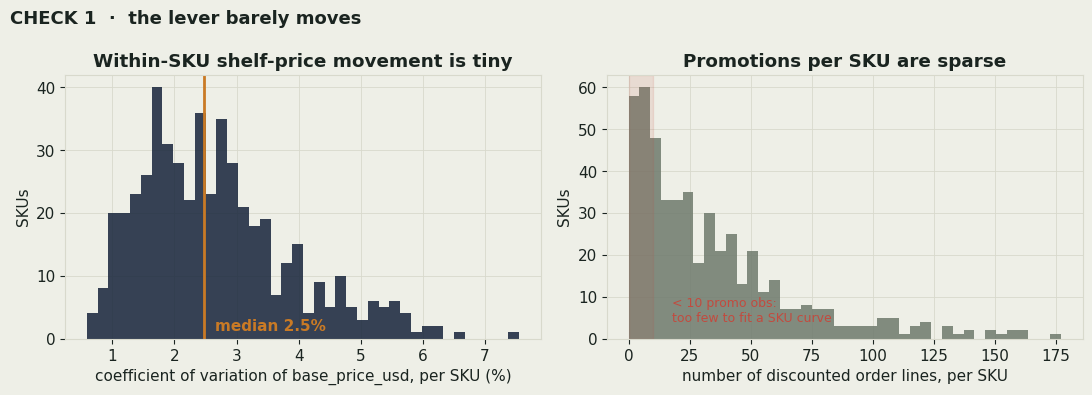

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(cv * 100, bins=40, color=NAVY, alpha=.85)
ax[0].axvline(cv.median() * 100, color=OCHRE, lw=2)
ax[0].annotate(f"median {cv.median()*100:.1f}%", (cv.median()*100, 0), xytext=(8, 6),
               textcoords="offset points", color=OCHRE, fontweight="bold")
ax[0].set_title("Within-SKU shelf-price movement is tiny", fontweight="bold")
ax[0].set_xlabel("coefficient of variation of base_price_usd, per SKU (%)")
ax[0].set_ylabel("SKUs")

ax[1].hist(per_sku.n_promo, bins=40, color=SAGE, alpha=.85)
ax[1].axvspan(0, 10, color=RED, alpha=.12)
ax[1].annotate("< 10 promo obs:\ntoo few to fit a SKU curve", (10, 0), xytext=(14, 12),
               textcoords="offset points", color=RED, fontsize=9)
ax[1].set_title("Promotions per SKU are sparse", fontweight="bold")
ax[1].set_xlabel("number of discounted order lines, per SKU")
ax[1].set_ylabel("SKUs")

fig.suptitle("CHECK 1  ·  the lever barely moves", x=.01, ha="left", fontsize=13, fontweight="bold")
savefig(fig, "check1_variation.png"); plt.show()

**Read.** List price drifts by ~2–3% over the year for a typical SKU, and only ~6% of
lines carry a discount — almost all bunched at a single ~20% depth. Per-SKU price
experiments this shallow cannot identify a per-SKU demand curve.

## 2 · The regression explains almost none of the variance

We run the project's own elasticity spec — `ln(qty)` on `ln(base_price)` and
`ln(1 − discount)` with SKU × period fixed effects — first pooled by **category**, then
**per SKU**. A model worth building on should explain a non-trivial share of demand
variation.

In [5]:
def demean(df, cols, groups):
    out = df.copy()
    for c in cols:
        for g in groups:
            out[c] = out[c] - out.groupby(g)[c].transform("mean") + out[c].mean()
    return out

def fit(g, fe=("sku_id", "period")):
    g = g[(g.base_price_usd > 0) & (g.order_qty > 0) & (g.discount_pct < 1)].copy()
    if g.sku_id.nunique() >= 2:
        fe = tuple(fe)
    else:
        fe = ("period",)                       # single SKU: its FE is absorbed already
    if len(g) < 30 or g.base_price_usd.nunique() < 5:
        return None
    g["ln_q"]  = np.log(g.order_qty)
    g["ln_p"]  = np.log(g.base_price_usd)
    g["ln_d"]  = np.log(1 - g.discount_pct + 1e-6)
    d = demean(g, ["ln_q", "ln_p", "ln_d"], list(fe))
    X = np.column_stack([np.ones(len(d)), d.ln_p, d.ln_d])
    beta, *_ = np.linalg.lstsq(X, d.ln_q.values, rcond=None)
    resid = d.ln_q.values - X @ beta
    ss_tot = np.sum((d.ln_q.values - d.ln_q.mean()) ** 2)
    r2 = 1 - np.sum(resid ** 2) / ss_tot if ss_tot > 0 else np.nan
    return {"elasticity": float(beta[1]), "r2": float(r2), "n": len(d)}

cat_fit = {c: fit(g) for c, g in o.groupby("category")}
cat_df = pd.DataFrame(cat_fit).T
print("Category-level fit:")
print(cat_df.round(3).to_string())

sku_rows = {s: fit(g) for s, g in o.groupby("sku_id")}
sku_df = pd.DataFrame({k: v for k, v in sku_rows.items() if v}).T
sku_df["category"] = sku.set_index("sku_id").category.reindex(sku_df.index).values
print(f"\nPer-SKU fits that converged: {len(sku_df)} of {o.sku_id.nunique()}")
print(f"  median R2            : {sku_df.r2.median():.3f}")
print(f"  elasticity sign wrong (>0): {(sku_df.elasticity > 0).mean():.1%}")
print(f"  |elasticity| > 8 (implausible): {(sku_df.elasticity.abs() > 8).mean():.1%}")

Category-level fit:
                        elasticity     r2        n
Beverages                   -1.057  0.008  61320.0
Dairy & Bakery              -1.245  0.026  60820.0
Frozen Foods                -3.495  0.062  55970.0
Grocery                     -1.832  0.020  62963.0
Snacks & Confectionery      -3.597  0.060  62286.0



Per-SKU fits that converged: 495 of 500
  median R2            : 0.002
  elasticity sign wrong (>0): 97.0%
  |elasticity| > 8 (implausible): 0.0%


saved output/diagnostic/check2_signal.png


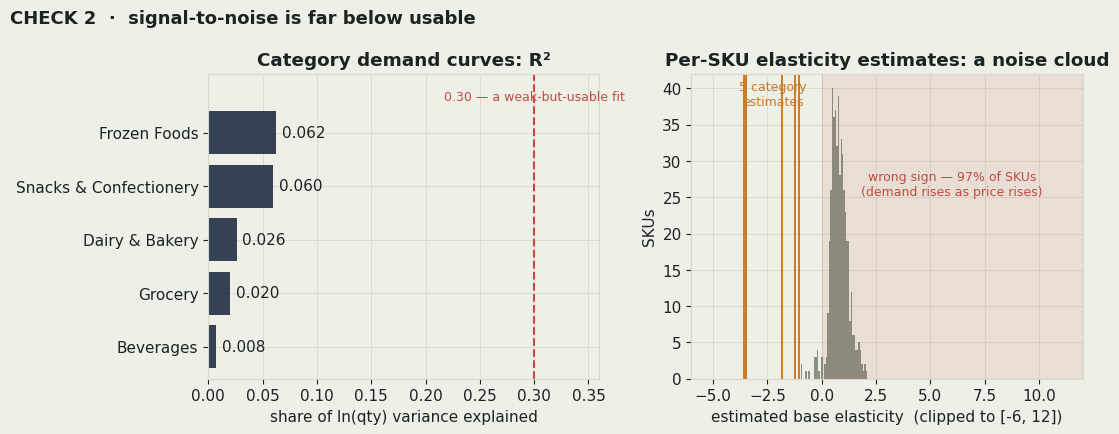

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))

c = cat_df.sort_values("r2")
ax[0].barh(c.index, c.r2, color=NAVY, alpha=.85)
ax[0].axvline(0.30, color=RED, lw=1.5, ls="--")
ax[0].text(0.30, 4.55, "0.30 — a weak-but-usable fit", color=RED, fontsize=9,
           ha="center", va="bottom")
for y, v in enumerate(c.r2):
    ax[0].annotate(f"{v:.3f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center")
ax[0].set_xlim(0, 0.36)
ax[0].set_ylim(-0.6, 5.1)
ax[0].set_title("Category demand curves: R²", fontweight="bold")
ax[0].set_xlabel("share of ln(qty) variance explained")

clip = sku_df.elasticity.clip(-6, 12)
ax[1].hist(clip, bins=45, color=SAGE, alpha=.8)
ax[1].axvspan(0, 12, color=RED, alpha=.10)
for _, r in cat_df.iterrows():
    ax[1].axvline(r.elasticity, color=OCHRE, lw=1.4)
ax[1].set_xlim(-6, 12)
ymax = ax[1].get_ylim()[1]
ax[1].text(cat_df.elasticity.mean(), ymax * .98, "5 category\nestimates", color=OCHRE,
           fontsize=9, ha="center", va="top")
ax[1].text(6, ymax * .60, f"wrong sign — {(sku_df.elasticity > 0).mean():.0%} of SKUs\n"
           "(demand rises as price rises)", color=RED, fontsize=9, ha="center")
ax[1].set_title("Per-SKU elasticity estimates: a noise cloud", fontweight="bold")
ax[1].set_xlabel("estimated base elasticity  (clipped to [-6, 12])")
ax[1].set_ylabel("SKUs")

fig.suptitle("CHECK 2  ·  signal-to-noise is far below usable", x=.01, ha="left",
             fontsize=13, fontweight="bold")
savefig(fig, "check2_signal.png"); plt.show()

**Read.** Pooled to category the fit tops out around R² 0.06 — 94%+ of demand movement is
*not* price. Per SKU it is worse: median R² ≈ 0.002, and ~97% of fits come back with the
*wrong sign* (demand rising as price rises) — endogeneity and noise, not a demand curve.
The per-SKU elasticity the charter wants "at SKU level" is not recoverable from this data.

## 3 · The only grain the data supports is one you can't act on

With per-SKU estimation off the table, elasticity collapses to **5 category numbers**
(or 10 with a price-tier split). As a SKU feature that means *zero* within-category
variance — it is `category` wearing a different label.

In [7]:
feat = pd.read_csv(f"{SEG}/sku_feature_matrix_annual.csv")
within_var = feat.groupby("category").elasticity_base.var().fillna(0)
print("within-category variance of elasticity_base (as used in the feature matrix):")
print(within_var.to_string())
print(f"\ndistinct elasticity_base values across 500 SKUs: {feat.elasticity_base.nunique()}")

within-category variance of elasticity_base (as used in the feature matrix):
category
Beverages                 0.0
Dairy & Bakery            0.0
Frozen Foods              0.0
Grocery                   0.0
Snacks & Confectionery    0.0

distinct elasticity_base values across 500 SKUs: 5


saved output/diagnostic/check3_grain.png


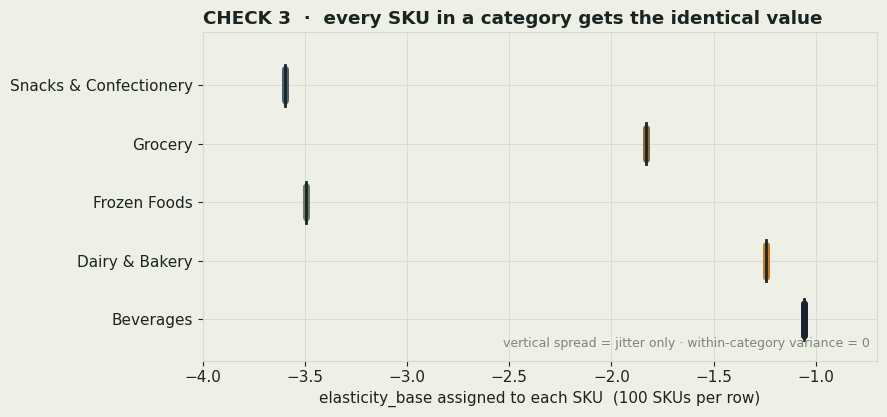

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.3))
rng = np.random.default_rng(0)
for i, cat in enumerate(CATS):
    sub = feat[feat.category == cat]
    ax.scatter(sub.elasticity_base, i + (rng.random(len(sub)) - .5) * .55,
               s=14, color=CAT_C[cat], alpha=.6)
    ax.plot([sub.elasticity_base.iloc[0]] * 2, [i - .35, i + .35], color=INK, lw=2)
ax.set_yticks(range(len(CATS))); ax.set_yticklabels(CATS)
ax.set_ylim(-0.7, len(CATS) - 0.1)
ax.set_xlim(-4.0, -0.7)
ax.set_xlabel("elasticity_base assigned to each SKU  (100 SKUs per row)")
ax.set_title("CHECK 3  ·  every SKU in a category gets the identical value",
             fontweight="bold", loc="left")
ax.text(0.99, 0.04, "vertical spread = jitter only · within-category variance = 0",
        transform=ax.transAxes, ha="right", fontsize=9, color=MUTED)
savefig(fig, "check3_grain.png"); plt.show()

**Read.** You cannot discount "Frozen Foods" — you discount SKU0412 at one DC next week.
A feature with five values and no within-category spread carries no SKU-level signal for
either clustering or targeting.

## 4 · It is redundant with features the clustering already uses

`segmentation_v2.py` deliberately keeps elasticity **out** of `CLUSTER_COLS` (comment:
*"used for profiling only, never clustering math"*). This check shows why that is the
right call: whatever category-pooled elasticity encodes is already carried by price,
margin and category structure.

In [9]:
num = ["list_price_usd", "margin_pct", "demand_cv", "revenue_total",
       "lead_time_mean_days", "stockout_rate", "shelf_life_days"]
corr = feat[num + ["elasticity_base"]].corr(method="spearman")["elasticity_base"].drop("elasticity_base")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
print("Spearman corr of elasticity_base with existing cluster-candidate features:")
print(corr.round(2).to_string())

anova = pd.read_csv(f"{SEG}/cluster_anova_annual.csv")
clu = pd.read_csv(f"{SEG}/sku_clusters_annual.csv")[["sku_id", "cluster"]]
m = feat.merge(clu, on="sku_id")
from scipy import stats
grp = [g.elasticity_base.values for _, g in m.groupby("cluster")]
f_el, p_el = stats.f_oneway(*grp)
print(f"\nANOVA F of elasticity_base across the existing clusters: {f_el:.1f} (p={p_el:.3g})")
print("  vs the features actually used for clustering:")
print(anova.set_index("feature")["f_statistic"].to_string())

Spearman corr of elasticity_base with existing cluster-candidate features:
margin_pct            -0.37
demand_cv             -0.22
stockout_rate         -0.17
shelf_life_days       -0.17
list_price_usd         0.02
revenue_total          0.02
lead_time_mean_days   -0.01



ANOVA F of elasticity_base across the existing clusters: 10.4 (p=3.6e-05)
  vs the features actually used for clustering:
feature
lead_time_std_days      1539.66
list_price_usd           352.21
lead_time_mean_days      236.56
revenue_total            128.43
stockout_rate              2.81
demand_cv                  2.68
supply_adherence_std       2.44
forecast_mape              0.33
shelf_life_days            0.15
margin_pct                 0.07


saved output/diagnostic/check4_redundancy.png


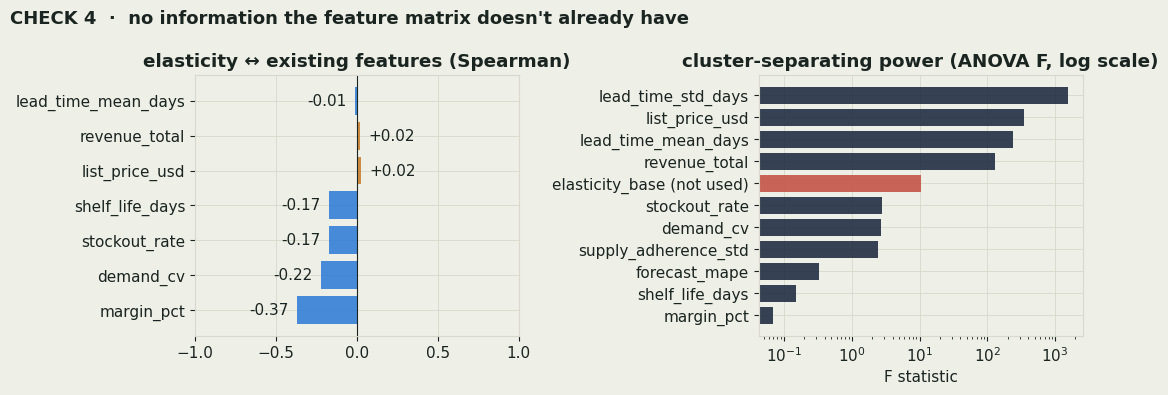

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].barh(corr.index, corr.values,
           color=[BLUE if v < 0 else OCHRE for v in corr.values], alpha=.85)
ax[0].axvline(0, color=INK, lw=.8)
for y, v in enumerate(corr.values):
    ax[0].annotate(f"{v:+.2f}", (v, y), xytext=(6 if v >= 0 else -6, 0),
                   textcoords="offset points", va="center",
                   ha="left" if v >= 0 else "right")
ax[0].set_title("elasticity ↔ existing features (Spearman)", fontweight="bold")
ax[0].set_xlim(-1, 1)

a = anova.set_index("feature")["f_statistic"].sort_values()
colors = [MUTED] * len(a)
a2 = pd.concat([a, pd.Series({"elasticity_base (not used)": f_el})]).sort_values()
colors = [RED if i == "elasticity_base (not used)" else NAVY for i in a2.index]
ax[1].barh(a2.index, a2.values, color=colors, alpha=.85)
ax[1].set_xscale("log")
ax[1].set_title("cluster-separating power (ANOVA F, log scale)", fontweight="bold")
ax[1].set_xlabel("F statistic")

fig.suptitle("CHECK 4  ·  no information the feature matrix doesn't already have",
             x=.01, ha="left", fontsize=13, fontweight="bold")
savefig(fig, "check4_redundancy.png"); plt.show()

**Read.** Elasticity's strongest tie is to `margin_pct` (ρ ≈ −0.37); its ANOVA F against
the existing clusters (~10) is one to two orders of magnitude below the features that
actually define them (`list_price_usd` ≈ 352, `lead_time_std_days` ≈ 1540). And because
the feature *is* category relabeled, the little separation it shows is just category
composition. Adding it to `CLUSTER_COLS` injects category membership, not new structure —
which is exactly why `segmentation_v2.py` leaves it out.

## 5 · The economic payoff points the other way

The charter's headline elasticity deliverable is the **price ↔ inventory exchange rate**:
`$1 of price flexibility = $Y of safety stock`. Rather than re-derive it here we read the
committed result from `output/findings.json` (produced by `price_elasticity_analysis.ipynb`
against real MEIO output and `cost_parameters.csv`) and set it beside what MEIO's own
retune is worth.

In [11]:
meio = pd.read_csv(f"{MEIO}/meio_summary_by_category.csv")
meio_savings = meio.delta_usd.abs().sum()

with open("output/findings.json") as f:
    F = json.load(f)
xr = pd.DataFrame(F["exchange_rate"])[
    ["category", "elasticity_base", "inv_annual_cost_usd", "price_buffer_cost_usd",
     "exchange_rate", "routing"]]
port = F["portfolio"]["exchange_rate"]
port_inv, port_price = F["portfolio"]["inv_annual_cost_usd"], F["portfolio"]["price_buffer_cost_usd"]

print(xr.to_string(index=False))
print(f"\nportfolio exchange rate : {port:.2f}x   (>1 = price cheaper, <1 = inventory cheaper)")
print(f"  inventory carrying cost   : ${port_inv:,.0f}/yr")
print(f"  equivalent price-buffer   : ${port_price:,.0f}/yr")
print(f"safety stock $ removed by the MEIO retune : ${meio_savings:,.0f}/yr")

              category  elasticity_base  inv_annual_cost_usd  price_buffer_cost_usd  exchange_rate                             routing
          Frozen Foods           -3.495                51727                  42056           1.23             Balanced blend (~50/50)
Snacks & Confectionery           -3.597                75086                 115215           0.65 Inventory-dominant (≥75% inventory)
        Dairy & Bakery           -1.245                40112                  91086           0.44 Inventory-dominant (≥75% inventory)
               Grocery           -1.832                42797                 106963           0.40 Inventory-dominant (≥75% inventory)
             Beverages           -1.057               165119                 783558           0.21 Inventory-dominant (≥75% inventory)

portfolio exchange rate : 0.33x   (>1 = price cheaper, <1 = inventory cheaper)
  inventory carrying cost   : $374,841/yr
  equivalent price-buffer   : $1,138,878/yr
safety stock $ removed b

saved output/diagnostic/check5_payoff.png


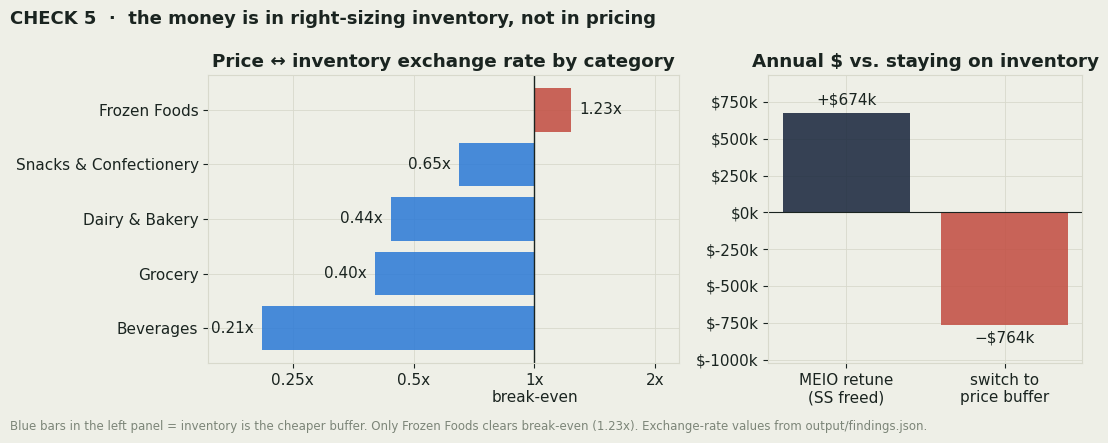

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [3, 2]})

d = xr.sort_values("exchange_rate")
logr = np.log2(d.exchange_rate)
ax[0].barh(d.category, logr, color=[BLUE if v < 0 else RED for v in logr], alpha=.85)
ax[0].axvline(0, color=INK, lw=1)
for y, (r, lr) in enumerate(zip(d.exchange_rate, logr)):
    ax[0].annotate(f"{r:.2f}x", (lr, y), xytext=(6 if lr >= 0 else -6, 0),
                   textcoords="offset points", va="center",
                   ha="left" if lr >= 0 else "right")
ax[0].set_xticks([-2, -1, 0, 1])
ax[0].set_xticklabels(["0.25x", "0.5x", "1x\nbreak-even", "2x"])
ax[0].set_xlim(-2.7, 1.2)
ax[0].set_title("Price ↔ inventory exchange rate by category", fontweight="bold")

bars = ax[1].bar(["MEIO retune\n(SS freed)", "switch to\nprice buffer"],
                 [meio_savings, port_inv - port_price],
                 color=[NAVY, RED], alpha=.85)
ax[1].axhline(0, color=INK, lw=.8)
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:.0f}k"))
ax[1].set_title("Annual $ vs. staying on inventory", fontweight="bold")
ax[1].bar_label(bars, padding=4,
                labels=[f"+${meio_savings/1e3:.0f}k", f"−${(port_price-port_inv)/1e3:.0f}k"])
ax[1].margins(y=.18)

fig.suptitle("CHECK 5  ·  the money is in right-sizing inventory, not in pricing",
             x=.01, ha="left", fontsize=13, fontweight="bold")
fig.text(.01, -.02, "Blue bars in the left panel = inventory is the cheaper buffer. "
         "Only Frozen Foods clears break-even (1.23x). Exchange-rate values from "
         "output/findings.json.", fontsize=8.5, color=MUTED)
savefig(fig, "check5_payoff.png"); plt.show()

**Read.** Only Frozen Foods clears break-even (1.23×); for the other four categories
inventory is the cheaper buffer and the portfolio rate is **0.33×** — replacing $1 of
safety stock with price costs about $3. Meanwhile MEIO's retune frees ~**$0.67M/yr** of
safety stock outright. Elasticity's flagship deliverable concludes *against* spending
build effort on price as a buffer.

## 6 · Effort vs. payoff — the verdict

| Elasticity workstream | Effort | Payoff on this data | Verdict |
|---|---|---|---|
| One-time **category** log–log estimate (already in `segmentation_v2.py` §2) | ~0 (done) | Useful as a profiling tag + a strategic "price is/ isn't a lever here" finding | **Keep** |
| **Per-SKU** elasticity estimation | High (hierarchical/Bayesian shrinkage to fight the sparsity) | Check 1–2: signal not identifiable; estimates are noise | **Skip** |
| **Elasticity-weighted clustering** (add to `CLUSTER_COLS`) | Low | Check 3–4: zero within-category variance, redundant, lowest ANOVA F | **Skip** |
| **Price-optimization / buffer-routing loop** | High (pricing engine, guardrails, sim) | Check 5: exchange rate < 1 for 4/5 categories; upside ≪ MEIO savings | **Skip / park** |
| Revisit trigger | — | A 2nd year of actuals, or a deliberate price-experimentation program that thickens the signal | Re-run this notebook then |

**Bottom line.** The category-level estimate that already exists is the right amount of
elasticity effort for this project. It costs nothing extra, supports the "is price a
lever" narrative, and feeds the exchange-rate finding. Everything past that — per-SKU
curves, elasticity-driven segmentation, a pricing loop — is not repaid by this dataset,
because the identifying price variation isn't there and the economics favor inventory.
The engineering budget belongs in MEIO, forecast-error sizing, and the segmentation
features that actually separate clusters.

In [13]:
verdict = {
    "check1_variation": {
        "promo_line_share": round((o.discount_pct > 0).mean(), 4),
        "within_sku_baseprice_cv_median": round(float(cv.median()), 4),
        "median_promo_lines_per_sku": int(per_sku.n_promo.median()),
    },
    "check2_signal": {
        "category_r2": {k: round(v["r2"], 4) for k, v in cat_fit.items() if v},
        "per_sku_median_r2": round(float(sku_df.r2.median()), 4),
        "per_sku_wrong_sign_share": round(float((sku_df.elasticity > 0).mean()), 4),
    },
    "check3_grain": {
        "distinct_elasticity_values_over_500_skus": int(feat.elasticity_base.nunique()),
        "within_category_variance": {k: round(float(v), 6) for k, v in within_var.items()},
    },
    "check4_redundancy": {
        "spearman_vs_features": {k: round(float(v), 3) for k, v in corr.items()},
        "anova_f_elasticity_vs_clusters": round(float(f_el), 2),
    },
    "check5_payoff": {
        "exchange_rate_by_category": dict(zip(xr.category, xr.exchange_rate.round(3))),
        "portfolio_exchange_rate": round(float(port), 3),
        "meio_safety_stock_savings_usd_yr": round(float(meio_savings)),
    },
    "verdict": "Keep the one-time category estimate; skip per-SKU estimation, "
               "elasticity-weighted clustering, and a pricing loop for this dataset.",
}
with open(f"{OUT}/elasticity_effort_verdict.json", "w") as f:
    json.dump(verdict, f, indent=2)
print(json.dumps(verdict, indent=2))

{
  "check1_variation": {
    "promo_line_share": 0.0571,
    "within_sku_baseprice_cv_median": 0.0247,
    "median_promo_lines_per_sku": 24
  },
  "check2_signal": {
    "category_r2": {
      "Beverages": 0.0075,
      "Dairy & Bakery": 0.0261,
      "Frozen Foods": 0.0624,
      "Grocery": 0.0204,
      "Snacks & Confectionery": 0.0598
    },
    "per_sku_median_r2": 0.0019,
    "per_sku_wrong_sign_share": 0.9697
  },
  "check3_grain": {
    "distinct_elasticity_values_over_500_skus": 5,
    "within_category_variance": {
      "Beverages": 0.0,
      "Dairy & Bakery": 0.0,
      "Frozen Foods": 0.0,
      "Grocery": 0.0,
      "Snacks & Confectionery": 0.0
    }
  },
  "check4_redundancy": {
    "spearman_vs_features": {
      "margin_pct": -0.369,
      "demand_cv": -0.222,
      "stockout_rate": -0.172,
      "shelf_life_days": -0.171,
      "list_price_usd": 0.022,
      "revenue_total": 0.017,
      "lead_time_mean_days": -0.014
    },
    "anova_f_elasticity_vs_clusters": 10.45